# Task 2: 3D Spatial Embryo & Heart Morphogenesis | 3D 空间形态发生建模实战

**为什么只预测表达、不改变 `obsm["spatial_3D"]` 会在 T2/T3 丢分？**

In Task 2 (Heart E9.25 → E9.5 extrapolation & Whole-Embryo interpolation), evaluation scores **both** gene expression (`de_score`, `celltype_de`, `energy_distance`) and **3D spatial geometry** (`d2_shape`, `sliced_wasserstein`, `occupancy_dice`, `scale_log_ratio`). Leaving `obsm["spatial_3D"]` static ignores organ expansion, axis rotation, and translation.


In [1]:
import json, sys, tempfile
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

for candidate in (Path.cwd(), Path.cwd().parent):
    if (candidate / "vec_nb_helpers.py").is_file() and str(candidate) not in sys.path:
        sys.path.insert(0, str(candidate))

from vec_nb_helpers import (
    SPATIAL_KEY,
    check_submission_contract,
    load_task_pair,
    predict_joint_3d_morphogenesis,
    predict_pseudobulk_shift,
    score_with_veckit_optional,
)

ref, target_full, source_tag = load_task_pair("T2")
print(f"Loaded T2 pair from: {source_tag} | ref={ref.shape}, target={target_full.shape}")
print("spatial_3D shape:", ref.obsm[SPATIAL_KEY].shape, "dtype:", ref.obsm[SPATIAL_KEY].dtype)


Loaded T2 pair from: veckit_sample:veckit | ref=(150, 500), target=(150, 500)
spatial_3D shape: (150, 3) dtype: float64


## 1. 表达迁移 vs 联合 3D 协方差形态映射 / Static Spatial vs Joint 3D Transform

同样采用严格的 `fit_target` / `eval_target` 不相交划分，避免信息泄漏，并比较 3D 半径尺度比（`RMS radius`）与 3D 空间投影变化。


In [2]:
rng = np.random.default_rng(7)
perm = rng.permutation(target_full.n_obs)
half = target_full.n_obs // 2
fit_target = target_full[perm[:half]].copy()
eval_target = target_full[perm[half:]].copy()

pred_static_spatial = predict_pseudobulk_shift(ref, np.zeros(ref.n_vars, dtype=np.float32), noise_std=0.0)
pred_joint_3d = predict_joint_3d_morphogenesis(ref, fit_target, shrink=0.80)

def rms_radius(adata):
    coords = np.asarray(adata.obsm[SPATIAL_KEY], dtype=np.float64)
    centered = coords - coords.mean(axis=0)
    return float(np.sqrt(np.mean(np.sum(centered ** 2, axis=1))))

r_eval = rms_radius(eval_target)
r_static = rms_radius(pred_static_spatial)
r_joint = rms_radius(pred_joint_3d)
print(f"Eval RMS 3D radius          : {r_eval:.3f}")
print(f"Static-spatial RMS 3D radius: {r_static:.3f} (scale ratio={r_static/r_eval:.3f})")
print(f"Joint-3D RMS 3D radius      : {r_joint:.3f} (scale ratio={r_joint/r_eval:.3f})")
print("Contract check (joint_3d):", check_submission_contract(pred_joint_3d, ref, require_spatial=True))


Eval RMS 3D radius          : 330.014
Static-spatial RMS 3D radius: 309.622 (scale ratio=0.938)
Joint-3D RMS 3D radius      : 329.823 (scale ratio=0.999)
Contract check (joint_3d): {'ok': True, 'n_obs': 150, 'n_vars': 500, 'var_names_exact_match': True, 'non_negative': True, 'all_finite': True, 'spatial_3D_valid': True}


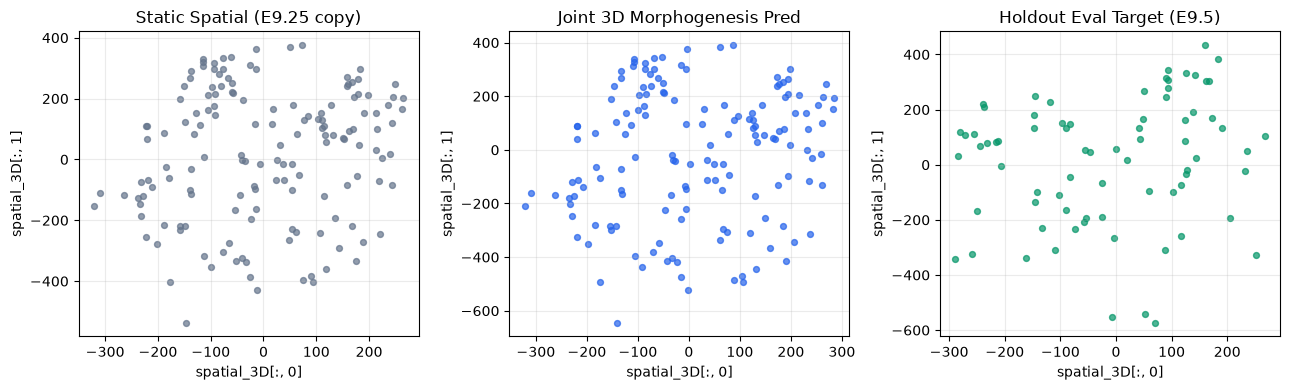

/Users/xinorigin/.cache/uv/archive-v0/XPnnoAnx1UFL1af0/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


veckit static_spatial: {
  "de_score": 0.0,
  "de_direction": 0.0,
  "energy_distance": 11.66751,
  "mmd_u": 0.27643,
  "variogram": 0.100333,
  "d2_shape": 0.01805,
  "sliced_wasserstein": 0.08292,
  "occupancy_dice": 0.3636,
  "scale_log_ratio": -0.0638,
  "count_log_ratio": 0.6931,
  "neighborhood_mmd": 0.61239,
  "pb_rel_err": 0.7677,
  "library_size_ratio": 0.017,
  "variance_ratio": 0.205,
  "composition_JSD": 0.025,
  "pseudobulk_pearson": 0.7877,
  "morans_I_agreement": 0.6025,
  "_de_raw": 0.0,
  "_de_chance": 0.3433,
  "_n_up": 67,
  "_n_dn": 0,
  "_sw_flip_spread": 0.00634,
  "_dice_voxel_over_nn": 1.6
}
veckit joint_3d      : {
  "de_score": 0.3182,
  "de_direction": 0.5734,
  "energy_distance": 6.94976,
  "mmd_u": 0.20988,
  "variogram": 0.094026,
  "d2_shape": 0.0276,
  "sliced_wasserstein": 0.08849,
  "occupancy_dice": 0.3065,
  "scale_log_ratio": -0.0006,
  "count_log_ratio": 0.6931,
  "neighborhood_mmd": 0.33449,
  "pb_rel_err": 0.3036,
  "library_size_ratio": 0.072,
 

/Users/xinorigin/.cache/uv/archive-v0/XPnnoAnx1UFL1af0/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.0))
s_static = np.asarray(pred_static_spatial.obsm[SPATIAL_KEY])
s_joint = np.asarray(pred_joint_3d.obsm[SPATIAL_KEY])
s_eval = np.asarray(eval_target.obsm[SPATIAL_KEY])

for ax, pts, title, col in [
    (axes[0], s_static, "Static Spatial (E9.25 copy)", "#64748b"),
    (axes[1], s_joint, "Joint 3D Morphogenesis Pred", "#2563eb"),
    (axes[2], s_eval, "Holdout Eval Target (E9.5)", "#059669"),
]:
    ax.scatter(pts[:, 0], pts[:, 1], s=18, alpha=0.7, color=col)
    ax.set_title(title)
    ax.set_xlabel("spatial_3D[:, 0]")
    ax.set_ylabel("spatial_3D[:, 1]")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

with tempfile.TemporaryDirectory() as tmp:
    tmp_p = Path(tmp)
    p_ref, p_tgt = tmp_p / "ref.h5ad", tmp_p / "tgt.h5ad"
    p_stat, p_jnt = tmp_p / "static.h5ad", tmp_p / "joint.h5ad"
    ref.write_h5ad(p_ref)
    eval_target.write_h5ad(p_tgt)
    pred_static_spatial.write_h5ad(p_stat)
    pred_joint_3d.write_h5ad(p_jnt)
    s_stat = score_with_veckit_optional("T2", p_stat, p_tgt, p_ref, setting="heart")
    s_jnt = score_with_veckit_optional("T2", p_jnt, p_tgt, p_ref, setting="heart")
    if s_stat and s_jnt:
        print("veckit static_spatial:", json.dumps(s_stat["metrics"], indent=2))
        print("veckit joint_3d      :", json.dumps(s_jnt["metrics"], indent=2))
